# Ground state search with a neural quantum state

This notebook is a minimal end-to-end example of a variational Monte Carlo (VMC) ground state search with `jVMC_exp`. We approximate the ground state of the 1D transverse-field Ising model (TFIM) with periodic boundary conditions,

$$
H = -\sum_{l=0}^{L-1} \sigma^z_l \sigma^z_{l+1} + g \sum_{l=0}^{L-1} \sigma^x_l ,
$$

and compare the variational energy with the exact result.

Every ground state search in `jVMC_exp` uses the same ingredients:

1. a **neural network** and the **variational wave function** (`NQS`) built from it,
2. a **sampler** that draws configurations from $|\psi(s)|^2$,
3. the **Hamiltonian**, built from local operators,
4. an **optimizer** (here stochastic reconfiguration, SR) with a **stepper** and a **learning rate**,
5. the call to `ground_state_search`, which runs the optimization loop.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import optax.schedules as scheduler
%matplotlib inline

The library is imported as `jVMC_exp`. The operators for discrete (spin) degrees of freedom are in `jVMC_exp.operator.discrete`.

In [10]:
# install the pip package and import jVMC
# !pip install jVMC

import jVMC_exp
import jVMC_exp.operator.discrete as op

## 1. Wave function and sampler

We use a complex-valued restricted Boltzmann machine (`CpxRBM`) with 8 hidden units as the ansatz. `NQS` wraps the network into a variational wave function for a chain of `L` spins (`sampleShape=L`); `batchSize` sets how many configurations are evaluated at once.

The `MCSampler` draws samples with the Metropolis algorithm:
- `SpinFlipZ2` proposes a single spin flip, and occasionally a global flip of all spins, which helps the chains move between the two $\mathbb{Z}_2$-symmetric sectors of the ferromagnetic phase;
- `numSamples` samples are collected per step from `numChains` parallel Markov chains;
- `thermalizationSweeps` sweeps are discarded before the samples are taken.

In [11]:
L = 10
g = -0.7

net = jVMC_exp.nets.CpxRBM(numHidden=8, bias=False)
n_steps = 100
n_samples = 2**12
n_chains = n_samples // 4
batch_size = n_samples

# Set up NQS and sampler 
psi = jVMC_exp.vqs.NQS(net, sampleShape=L, batchSize=batch_size, seed=123)
proposer = jVMC_exp.propose.SpinFlipZ2()
sampler = jVMC_exp.sampler.MCSampler(
    psi, 
    proposer, 
    key=123, 
    numChains=n_chains, 
    numSamples=n_samples, 
    thermalizationSweeps=25
)

## 2. Exact reference energy

The TFIM can be solved exactly by mapping it to free fermions. For a finite chain with periodic boundary conditions the ground state energy per site is

$$
\frac{E_0}{L} = -\frac{1}{L} \sum_{k} \sqrt{1 + g^2 - 2 g \cos k}, \qquad k = \frac{\pi}{L}(2n+1), \quad n = -\tfrac{L}{2}, \dots, \tfrac{L}{2}-1 .
$$

We use it as a benchmark for the variational result.

In [12]:
def energy_single_p_mode(h_t, P):
    return np.sqrt(1 + h_t**2 - 2 * h_t * np.cos(P))

def ground_state_energy_per_site(h_t, N):
    Ps =  0.5 * np.arange(- (N - 1), N - 1 + 2, 2)
    Ps = Ps * 2 * np.pi / N
    energies_p_modes =  np.array([energy_single_p_mode(h_t, P) for P in Ps])
    
    return - 1 / N * np.sum(energies_p_modes)

exact_energy = ground_state_energy_per_site(g, L)
print(exact_energy)

-1.127222500154964


## 3. Hamiltonian

Operators such as `SigmaZ(l)` and `SigmaX(l)` act on site `l`. They can be multiplied (operator products) and summed (with scalar coefficients) to build the Hamiltonian, as in the formula above. The `% L` implements the periodic boundary conditions.

In [13]:
# Set up hamiltonian
hamiltonian = 0
for l in range(L):
    hamiltonian += -1 * op.SigmaZ(l) * op.SigmaZ((l + 1) % L) + g * op.SigmaX(l)

## 4. Optimizer

- **Learning rate**: an `optax` schedule, constant at $5\cdot10^{-2}$ for the first 30% of the steps, then decaying linearly to $10^{-3}$. A constant float also works.
- **Stepper**: `Euler` performs the update $\theta \to \theta - \eta\, \delta\theta$, where $\eta$ is the learning rate.
- **Objective function**: `Observable(hamiltonian)` minimizes the expectation value of the Hamiltonian, i.e. the energy.
- **Optimizer**: `SR` (stochastic reconfiguration) computes the update $\delta\theta$ by solving $S\,\delta\theta = F$, with $S$ the quantum geometric tensor and $F$ the energy gradient. `diagonalShift` adds a constant to the diagonal of $S$ to regularize it, and `solver` chooses how the linear system is solved (`Pinv`: pseudo-inverse).

In [14]:
# Set up optimization
lr = scheduler.linear_schedule(5e-2, 1e-3, transition_steps=0.7*n_steps, transition_begin=0.3*n_steps)
stepper = jVMC_exp.stepper.Euler(lr)
loss_function = jVMC_exp.objective_function.Observable(hamiltonian)
solver = jVMC_exp.solver.Pinv()
opt = jVMC_exp.optimizer.SR(sampler, psi, diagonalShift=1e-3, solver=solver)

/home/msolionas/code/Custom_jVMC/jVMC_exp/optimizer/base.py:453: UserWarning: Naming convention changed: 'diag_shift' now adds a constant term to the diagonal, while 'diag_scale' multiplies the diagonal entries. This is the opposite of the previous convention.
  warnings.warn(


## 5. Run the optimization

`ground_state_search` runs `n_steps` optimization steps. The progress bar shows the current estimate of the **total** energy, its Monte Carlo error and the energy variance. At the end, the time spent in each part of the step is printed.

The returned dictionary contains the step numbers in `out["times"]` and, in `out["energy"]`, the lists `"mean"`, `"variance"` and `"MC_error"` of the energy at every step. Other observables can be measured during the optimization with the `observables` argument.

In [15]:
out = opt.ground_state_search(n_steps, loss_function, stepper)

100%|██████████| 100/100 [00:24<00:00,  4.10it/s, E=-1.1271e+01-6.8109e-06j ± 1.7370e-03 (Var = 1.2358e-02)]

Recorded timings:
    - sampling: 18.874404s
    - compute objective function and gradient: 2.566524s
    - solve: 2.215699s


## 6. Results

Left: the energy per site converges to the exact value. Right: the energy variance, which vanishes for an exact eigenstate, is a useful measure of the quality of the variational state that does not require knowing the exact energy.

Final relative error:  9.065309871123403e-05


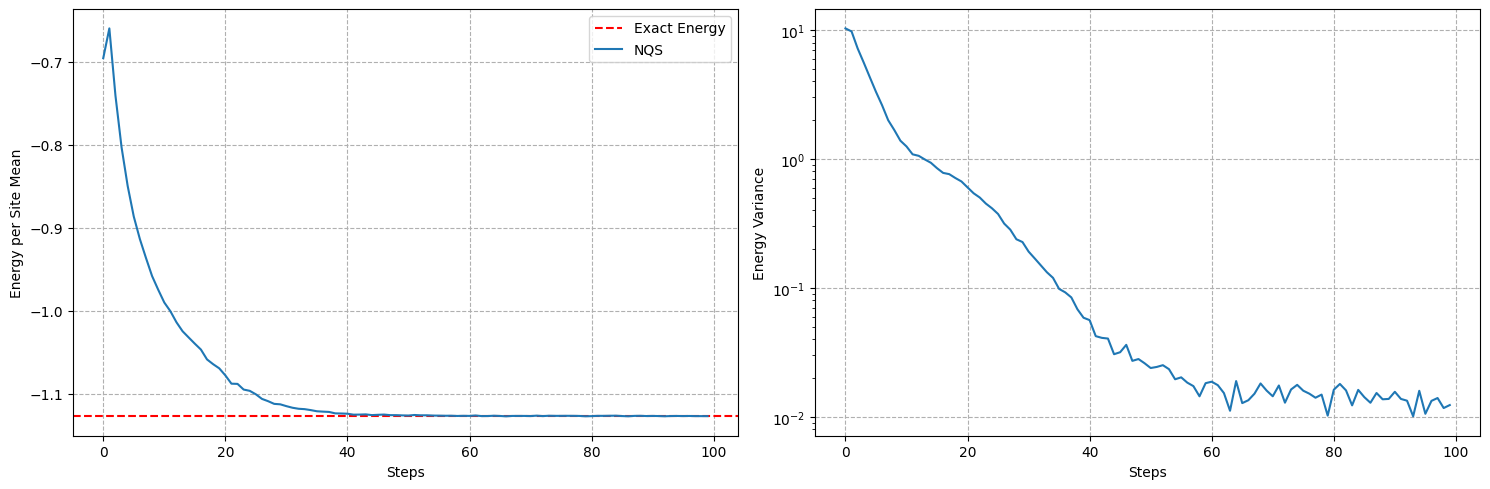

In [17]:
steps = out["times"]
energy_mean = np.array(out["energy"]["mean"]).real
energy_var = np.array(out["energy"]["variance"]).real

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.axhline(exact_energy, ls="--", color="red", label="Exact Energy")
plt.plot(steps, energy_mean / L, label="NQS")
plt.ylabel("Energy per Site Mean")
plt.xlabel("Steps")
plt.grid(ls="--")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(steps, energy_var)
plt.yscale("log")
plt.ylabel("Energy Variance")
plt.xlabel("Steps")
plt.grid(ls="--")

plt.tight_layout()

print("Final relative error: ", (energy_mean[-1] / L - exact_energy) / np.abs(exact_energy))